In [1]:
import warnings
warnings.filterwarnings('ignore')

import xarray as xr
from glob import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cmocean.cm as cmo
import gsw
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.signal import savgol_filter
import matplotlib.patches as patches

from load_profiles import compute_mld, compute_mld_density
from utils import get_shelf_edge, nearest, prepare_eddies2plot, subplots_structure, make_map

In [2]:
import matplotlib as mpl

mpl.rcParams['xtick.labelsize'] = 12
mpl.rcParams['ytick.labelsize'] = 12

In [3]:
extent =[-47.5, -37.5, -28, -20.62] # max lat fits the gebco data I have for sheld egde contour

# set relative path to the source file
datadir = './../data/glider'
savedir = './../figures'

box = [-47.5, -37.5, -28, -20] 
timerange = [pd.to_datetime('2022-03-01'), 
             pd.to_datetime('2022-04-01')]

In [5]:
# loading eddies
ds_locs = xr.open_dataset(f"{datadir}/../eddies_sanagu2022_daily.nc")

ds = xr.open_dataset(f"{datadir}/sg576_Azul_19")

# add density
ds['dens'] = gsw.sigma0(ds['salinity'], ds['temperature'])

# get shelf edge
edge = get_shelf_edge()

In [6]:
ds = ds.sel(time=slice(timerange[0], timerange[1]))
ds

<xarray.Dataset>
Dimensions:           (update: 1, time_raw: 540700, variables: 6, time: 132,
                       depth: 46)
Coordinates:
  * update            (update) int32 0
  * time              (time) datetime64[ns] 2022-03-01T05:25:18.500000 ... 20...
  * time_raw          (time_raw) datetime64[ns] 2021-11-22T11:32:30 ... 2022-...
  * depth             (depth) float32 5.0 10.0 15.0 20.0 ... 900.0 950.0 1e+03
Dimensions without coordinates: variables
Data variables: (12/27)
    qc                (time_raw, variables) int32 ...
    dive_start        (time) int32 ...
    dive_end          (time) int32 ...
    start_date        (time) datetime64[ns] ...
    end_date          (time) datetime64[ns] ...
    down_up           (time_raw) int32 ...
    ...                ...
    chlorophyll_raw   (time_raw) float32 ...
    cdom              (time, depth) float32 ...
    cdom_raw          (time_raw) float32 ...
    DAC               (time) float32 ...
    DAC_DIR           (time) float32 ...
    dens              (time, depth) float64 23.89 23.88 23.87 ... 27.26 nan
Attributes:
    title:            Glider Data
    glider_id:        576
    julian_day_unit:  seconds since 1970-01-01 00:00:00 UTC
    _FillValue:       -9999.9999

In [7]:
ds['pressure'] = gsw.p_from_z((-1)*ds['depth'], ds['latitude'])
ds['SA'] = gsw.SA_from_SP(ds['salinity'], ds['pressure'], ds['longitude'], ds['latitude'])
ds['CT'] = gsw.CT_from_t(ds['SA'], ds['temperature'], ds['pressure'])
ds['dens'] = gsw.sigma0(ds['SA'], ds['CT'])

# fixing attributes
ds['SA'].attrs['long_name'] = 'absolute salinity'
ds['SA'].attrs['standard_name'] = 'salt'
ds['SA'].attrs['units'] = 'g/kg'

ds['CT'].attrs['long_name'] = 'temperature'
ds['CT'].attrs['standard_name'] = 'temp'
ds['CT'].attrs['units'] = 'oC'

In [8]:
mld_list = []
for cast in range(ds.dims['time']):
    prof = ds.isel(time=cast)
    
    mld = compute_mld(prof['depth'], prof['SA'], prof['CT'], prof['dens'])
    
    mld_list.append(mld)
    
ds['mld'] = (('time'), mld_list)
ds['mld_smoothed'] = (('time'), savgol_filter(ds['mld'], 15, 2))

In [10]:
for k,item in chunks.items():
    ds_chunk = ds.sel(time=slice(item[0], item[1]))

    distance = gsw.distance([ds_chunk.longitude.values[0],ds_chunk.longitude.values[-1]],
                            [ds_chunk.latitude.values[0],ds_chunk.latitude.values[-1]])

    distance = distance/1e3
    print(f"{k}: {distance[0]:0.2f} km")

[a]: 78.83 km
[b]: 27.46 km
[c]: 77.36 km


In [13]:
# defining chunks to help in the discussion of the Smax advection
chunks = {
    'offshore': ['2022-03-03', '2022-03-10', 'lime'],
    'loop': ['2022-03-12', '2022-03-19', 'k'],
    'shelf': ['2022-03-21', '2022-03-26', 'white']
}

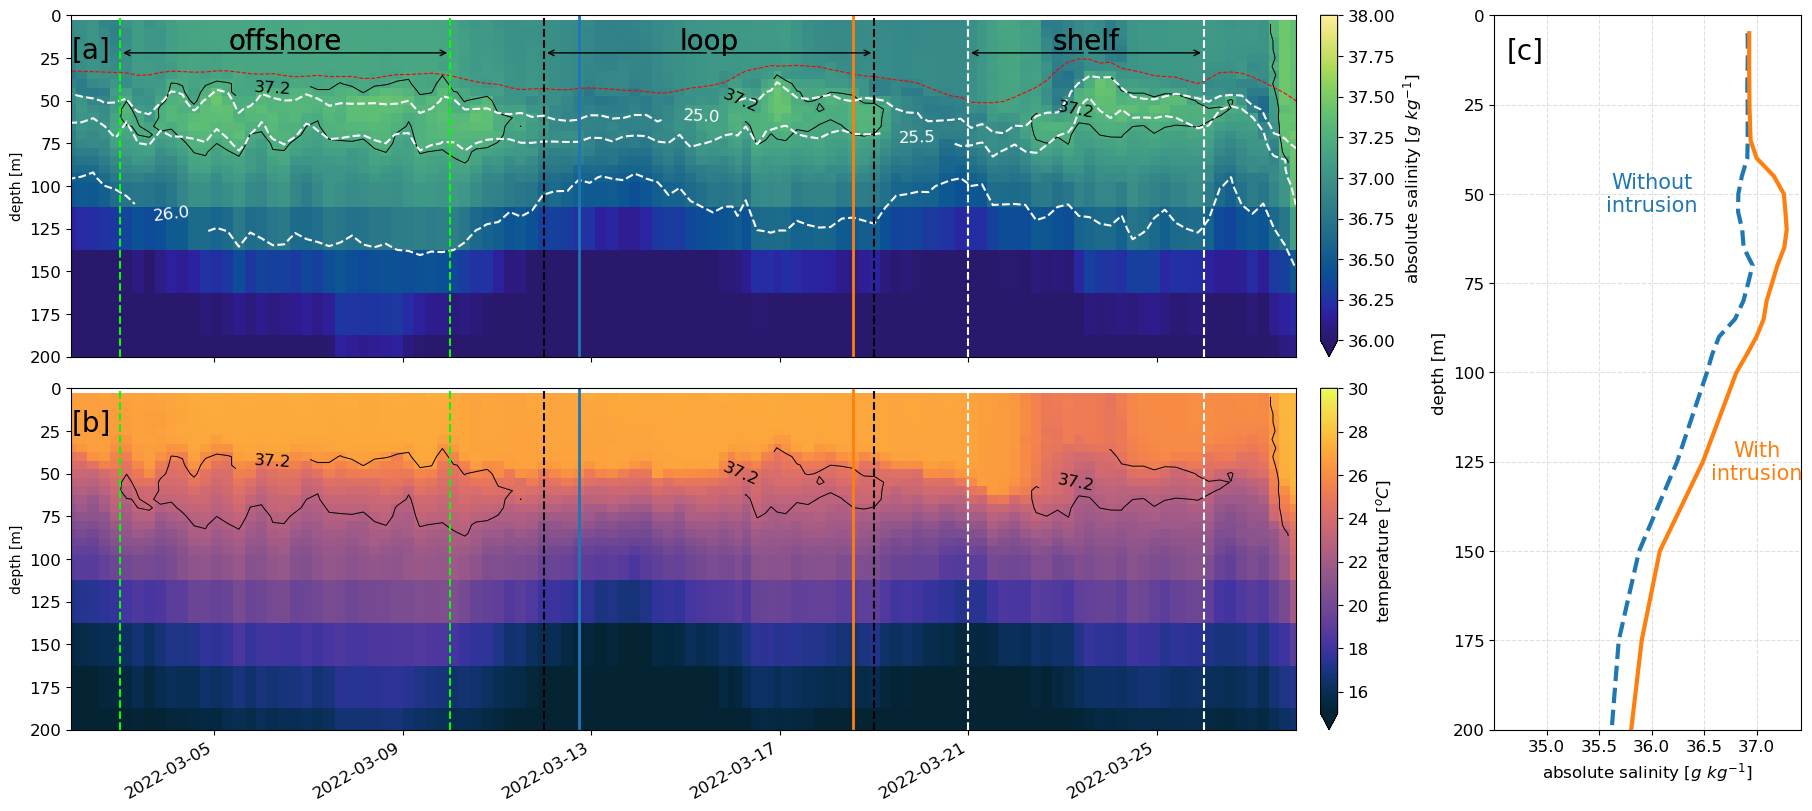

In [15]:
fig = plt.figure(layout="constrained", figsize=(18, 8))
axd = fig.subplot_mosaic(
    """
    AAAAC
    BBBBC
    """
)

axes_main = [axd[key] for key in ['A', 'B', 'C']]

##################################################################################################
axes = axes_main[:2]

## # __ SALINITY __ # ##
ax = axes[0]

ax.set_title("[a]", loc='left', fontsize=20, y=0.85)

pc = ds['SA'].plot.pcolormesh(ax=ax, x='time', y='depth', cmap=cmo.haline, vmin=36, vmax=38, cbar_kwargs={'pad': 0.02})
pc.colorbar.set_label(r'absolute salinity [$g\ kg^{-1}$]', fontsize=12)
cr1 = ds['SA'].plot.contour(ax=ax, levels=[37.2], colors='k', linewidths=[0.7], x='time', y='depth')
cr2 = ds['dens'].plot.contour(ax=ax, x='time', y='depth', levels=[25, 25.5, 26], colors='w', linestyles=['dashed'], lw=[0.2])

ax.clabel(cr1, fmt='%2.1f', colors='k', fontsize=12)
ax.clabel(cr2, fmt='%2.1f', colors='w', fontsize=12)

## # __ TEMPERATURE __ # ##
ax = axes[1]
ax.set_title("[b]", loc='left', fontsize=20, y=0.85)

pc = ds['CT'].plot.pcolormesh(ax=ax, x='time', y='depth', cmap=cmo.thermal, vmin=15, vmax=30, cbar_kwargs={'pad': 0.02})
pc.colorbar.set_label(r'temperature [$^oC$]', fontsize=12)

cr1 = ds['SA'].plot.contour(ax=ax, levels=[37.2], colors='k', linewidths=[0.7], x='time', y='depth')

ax.clabel(cr1, fmt='%2.1f', colors='k', fontsize=12)
# axes[1].clabel(cr2, fmt='%2.1f', colors='w', fontsize=10)

_ = [ax.set_ylim([0,200]) for ax in axes]
_ = [ax.invert_yaxis() for ax in axes]

_ = [ax.set_xlabel('') for ax in axes]

# adding smoothed MLD
ds['mld_smoothed'].plot(ax=axes[0], ls='--', c='r', lw=.8)

# adding chunks
for letter,chunk in chunks.items():
    period = [pd.to_datetime(chunk[0]), pd.to_datetime(chunk[1])]
    color = chunk[2]
    central_dt = period[0] + (period[1] - period[0]) / 2
    
    _ = [ax.axvline(period[0], c=color, lw=1.5, ls='dashed') for ax in axes]
    _ = [ax.axvline(period[1], c=color, lw=1.5, ls='dashed') for ax in axes]
    _ = [axes[0].text(central_dt, 20, 
                 letter, fontsize=20, ha='center') for ax in axes]
    
    # Setas (usando annotate)
    arrowprops = dict(arrowstyle="->", color='k')
    for ax in axes[:1]:
        # Do texto ao início
        ax.annotate('', xy=(period[0], 22), xytext=(central_dt, 22), arrowprops=arrowprops)
        
        # Do texto ao fim
        ax.annotate('', xy=(period[1], 22), xytext=(central_dt, 22), arrowprops=arrowprops)


_ = [ax.set_xlim([pd.to_datetime('2022-03-02') - pd.Timedelta(hours=1), 
                  pd.to_datetime('2022-03-28') - pd.Timedelta(hours=1)]) for ax in axes]

axes[0].set_xlabel('')
axes[0].set_xticklabels('')

axes[0].set_ylabel('depth [m]')
axes[1].set_ylabel('depth [m]')

### adding vertical profiles extracted for the comparison of the advective theory
firstProfile = pd.to_datetime('2022-03-12 17:33')
secndProfile = pd.to_datetime('2022-03-18 13:24')
_ = [ax.axvline(firstProfile, c='tab:blue', lw=2, ymin=-20) for ax in axes]
_ = [ax.axvline(secndProfile, c='tab:orange', lw=2, ) for ax in axes]
##################################################################################################


ax = axes_main[2]
styles = ['--', '-']

for i,t in enumerate(['2022-03-12 17:33','2022-03-18 13:24']):
    ds.sel(time=t)['SA'].plot(ax=ax, y='depth', ls=styles[i], lw=3.)

ax.grid(True, ls='--', alpha=.4)
ax.set_title('')
ax.set_ylabel('depth [m]', fontsize=12)
ax.set_xlabel(r'absolute salinity [$g\ kg^{-1}$]', fontsize=12)
ax.invert_yaxis()
ax.set_ylim([200,0])
_ = plt.xticks(fontsize=12)
_ = plt.yticks(fontsize=12)

ax.text(36.0, 50, 'Without\nintrusion', fontsize=15, color='tab:blue', ha='center', va='center')
ax.text(37.0, 125, 'With\nintrusion', fontsize=15, color='tab:orange', ha='center', va='center')

ax.text(34.8, 10, '[c]', fontsize=20, color='k', ha='center', va='center')

style = "Simple, tail_width=0.5, head_width=4, head_length=8"
kw = dict(arrowstyle=style, color="tab:blue")
a1 = patches.FancyArrowPatch((36, 58), (36.8, 70), 
                             connectionstyle="arc3,rad=.2", **kw)

style = "Simple, tail_width=0.5, head_width=4, head_length=8"
kw = dict(arrowstyle=style, color="tab:orange")
a2 = patches.FancyArrowPatch((37, 120), (37.3, 62), 
                             connectionstyle="arc3,rad=.2", **kw)
for a in [a1, a2]:
    plt.gca().add_patch(a)    
    
fig.patch.set_alpha(1.0)
# plt.subplots_adjust(hspace=.05)
plt.savefig('../figures/manuscript/00_manuscript_glider_transect.png', bbox_inches="tight", dpi=300)